In [227]:
import pandas as pd
import xml.etree.ElementTree as ET
from seaborn import boxplot
from matplotlib.pyplot import scatter
from seaborn import heatmap
from phik import phik_matrix

In [228]:
tree = ET.parse("raw_data/restaurants_train_russian_raw.xml")
root = tree.getroot()
root.tag

'Reviews'

In [229]:
reviews: list = root.findall("Review")
reviews_count: int = len(reviews)
reviews_count

312

In [230]:
sentences_data = []
opinions_data = []

In [231]:
for review in reviews:
    rid = review.get("rid")
    sentences = review.find("sentences")

    if sentences is not None:
        sentences = sentences.findall("sentence")

        for sentence in sentences:
            sentence_id = sentence.get("id")
            sentence_text = sentence.find("text").text
            sentences_data.append({
                "review_id": rid,
                "sentence_id": sentence_id,
                "text": sentence_text
            })

            opinions = sentence.find("Opinions")

            if opinions is not None:

                opinions = opinions.findall("Opinion")
                opinions_count = len(opinions)

                for opinion in opinions:
                    category = opinion.get("category")
                    polarity = opinion.get("polarity")
                    target = opinion.get("target")
                    opinions_data.append({
                        "sentence_id": sentence_id,
                        "category": category,
                        "polarity": polarity,
                        "target": target,
                        "from": opinion.get("from"),
                        "to": opinion.get("to")
                    })



In [232]:
sentences_df = pd.DataFrame(sentences_data)
opinions_df = pd.DataFrame(opinions_data)

In [233]:
sentences_df

,review_id,sentence_id,text
0,27925,27925:0,Добрый час суток.
1,27925,27925:1,Меня зовут Влада!
2,27925,27925:2,Я со своим молодым человеком и пару его друзей...
3,27925,27925:3,Обслуживание хорошее нас встретил метрдотель и...
4,27925,27925:4,"Он был в уютном уголке в конце главного зала, ..."
...,...,...,...
3650,9955,9955:0,Давно хотели сходить в это кафе(тем более живе...
3651,9955,9955:1,"Впечатления остались только хорошие,интерьер п..."
3652,9955,9955:2,"Готовят вкусно и достаточно быстро,на мой взгляд."
3653,9955,9955:3,"Обслуживала нас приятная,веселая девушка,успев..."


In [234]:
opinions_df

,sentence_id,category,polarity,target,from,to
0,27925:3,SERVICE#GENERAL,positive,Обслуживание,0,12
1,27925:3,SERVICE#GENERAL,positive,метрдотель,34,44
2,27925:4,AMBIENCE#GENERAL,positive,уголке,16,22
3,27925:4,AMBIENCE#GENERAL,positive,приглушенный свет,46,63
4,27925:6,FOOD#QUALITY,positive,блюд,53,57
...,...,...,...,...,...,...
4084,9955:1,AMBIENCE#GENERAL,positive,интерьер,36,44
4085,9955:2,FOOD#QUALITY,positive,NULL,0,0
4086,9955:3,SERVICE#GENERAL,positive,девушка,33,40
4087,9955:3,FOOD#PRICES,positive,скидку,91,97


In [235]:
sentences_df.shape

(3655, 3)

In [236]:
opinions_df.shape

(4089, 6)

In [237]:
merged_df = sentences_df.merge(opinions_df, how="left", on="sentence_id")
merged_df

,review_id,sentence_id,text,category,polarity,target,from,to
0,27925,27925:0,Добрый час суток.,NaN,NaN,NaN,NaN,NaN
1,27925,27925:1,Меня зовут Влада!,NaN,NaN,NaN,NaN,NaN
2,27925,27925:2,Я со своим молодым человеком и пару его друзей...,NaN,NaN,NaN,NaN,NaN
3,27925,27925:3,Обслуживание хорошее нас встретил метрдотель и...,SERVICE#GENERAL,positive,Обслуживание,0,12
4,27925,27925:3,Обслуживание хорошее нас встретил метрдотель и...,SERVICE#GENERAL,positive,метрдотель,34,44
...,...,...,...,...,...,...,...,...
5006,9955,9955:1,"Впечатления остались только хорошие,интерьер п...",AMBIENCE#GENERAL,positive,интерьер,36,44
5007,9955,9955:2,"Готовят вкусно и достаточно быстро,на мой взгляд.",FOOD#QUALITY,positive,NULL,0,0
5008,9955,9955:3,"Обслуживала нас приятная,веселая девушка,успев...",SERVICE#GENERAL,positive,девушка,33,40
5009,9955,9955:3,"Обслуживала нас приятная,веселая девушка,успев...",FOOD#PRICES,positive,скидку,91,97


In [238]:
print(f"Количество предложений: {sentences_df["sentence_id"].count()}")
print(f"Количество мнений: {opinions_df["sentence_id"].count()}")
print(f"Количество уникальных отзывов: {sentences_df["review_id"].nunique()}")
print(f"Количество предложений с мнениями: {opinions_df["sentence_id"].nunique()}")
print(f"Количество предложений без мнений: {merged_df["category"].isna().sum()}")
print(f"Пропуски по каждому признаку: \n{merged_df.isna().sum()}")


Количество предложений: 3655
Количество мнений: 4089
Количество уникальных отзывов: 312
Количество предложений с мнениями: 2733
Количество предложений без мнений: 922
Пропуски по каждому признаку: 
review_id        0
sentence_id      0
text             0
category       922
polarity       922
target         922
from           922
to             922
dtype: int64


In [239]:
opinions_df["general_category"] = opinions_df["category"].apply(lambda string: string[:string.find("#")])
opinions_df

,sentence_id,category,polarity,target,from,to,general_category
0,27925:3,SERVICE#GENERAL,positive,Обслуживание,0,12,SERVICE
1,27925:3,SERVICE#GENERAL,positive,метрдотель,34,44,SERVICE
2,27925:4,AMBIENCE#GENERAL,positive,уголке,16,22,AMBIENCE
3,27925:4,AMBIENCE#GENERAL,positive,приглушенный свет,46,63,AMBIENCE
4,27925:6,FOOD#QUALITY,positive,блюд,53,57,FOOD
...,...,...,...,...,...,...,...
4084,9955:1,AMBIENCE#GENERAL,positive,интерьер,36,44,AMBIENCE
4085,9955:2,FOOD#QUALITY,positive,NULL,0,0,FOOD
4086,9955:3,SERVICE#GENERAL,positive,девушка,33,40,SERVICE
4087,9955:3,FOOD#PRICES,positive,скидку,91,97,FOOD


In [240]:
opinions_categories_val_counts = opinions_df["category"].value_counts()
opinions_categories_val_counts

category
SERVICE#GENERAL             1066
FOOD#QUALITY                 973
AMBIENCE#GENERAL             710
RESTAURANT#GENERAL           698
FOOD#STYLE_OPTIONS           290
DRINKS#QUALITY                86
RESTAURANT#PRICES             71
FOOD#PRICES                   58
RESTAURANT#MISCELLANEOUS      43
DRINKS#STYLE_OPTIONS          41
LOCATION#GENERAL              36
DRINKS#PRICES                 17
Name: count, dtype: int64

<Axes: xlabel='general_category'>

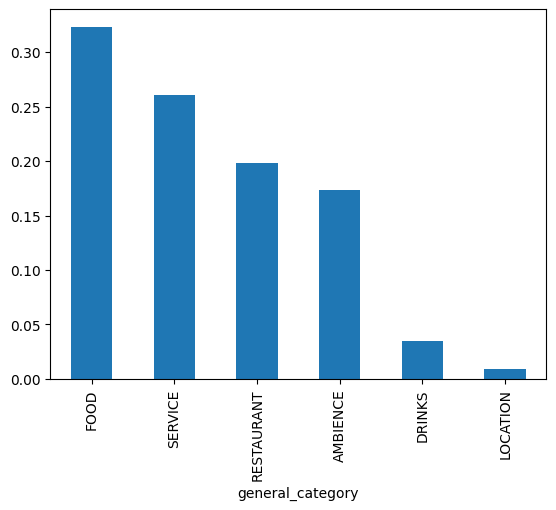

In [241]:
opinions_general_categories_val_counts = opinions_df["general_category"].value_counts(normalize=True)
opinions_general_categories_val_counts.plot.bar()

In [242]:
opinions_unique_categories = opinions_df["category"].unique()
opinions_general_categories = opinions_df["category"].apply(lambda string: string[:string.find("#")]).unique()

print(f"Уникальные категории: {opinions_unique_categories}")
print(f"Общие уникальные категории: {opinions_general_categories}")

Уникальные категории: ['SERVICE#GENERAL' 'AMBIENCE#GENERAL' 'FOOD#QUALITY' 'FOOD#PRICES'
 'FOOD#STYLE_OPTIONS' 'RESTAURANT#GENERAL' 'RESTAURANT#PRICES'
 'DRINKS#STYLE_OPTIONS' 'RESTAURANT#MISCELLANEOUS' 'DRINKS#QUALITY'
 'LOCATION#GENERAL' 'DRINKS#PRICES']
Общие уникальные категории: ['SERVICE' 'AMBIENCE' 'FOOD' 'RESTAURANT' 'DRINKS' 'LOCATION']


<Axes: xlabel='polarity'>

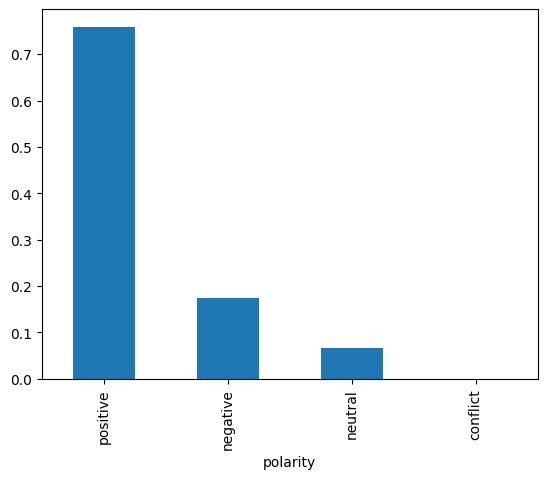

In [243]:
opinions_polarity_val_counts = opinions_df["polarity"].value_counts(normalize=True)
opinions_polarity_val_counts.plot.bar()

In [244]:
opinions_df["polarity"].value_counts(normalize=True)

polarity
positive    0.758865
negative    0.173392
neutral     0.067498
conflict    0.000245
Name: proportion, dtype: float64

<Axes: ylabel='general_category'>

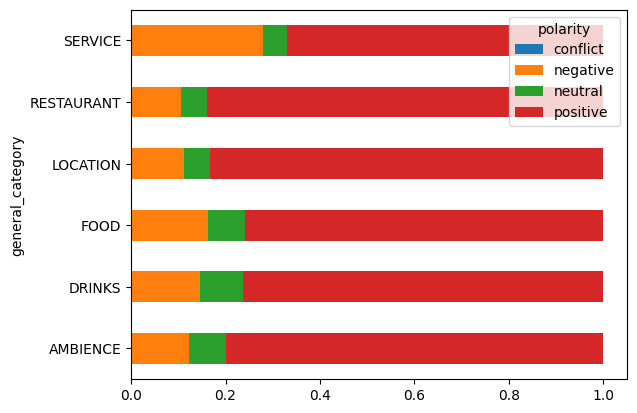

In [245]:
polarity_counts_df = pd.crosstab(opinions_df["general_category"], opinions_df["polarity"])
polarity_share_df = pd.crosstab(opinions_df["general_category"], opinions_df["polarity"], normalize="index")
polarity_share_df.plot.barh(stacked=True)

In [246]:
polarity_counts_df

polarity,conflict,negative,neutral,positive
general_category,,,,
AMBIENCE,0,87,56,567
DRINKS,0,21,13,110
FOOD,1,213,106,1001
LOCATION,0,4,2,30
RESTAURANT,0,86,44,682
SERVICE,0,298,55,713


In [247]:
polarity_share_df

polarity,conflict,negative,neutral,positive
general_category,,,,
AMBIENCE,0.000000,0.122535,0.078873,0.798592
DRINKS,0.000000,0.145833,0.090278,0.763889
FOOD,0.000757,0.161241,0.080242,0.757759
LOCATION,0.000000,0.111111,0.055556,0.833333
RESTAURANT,0.000000,0.105911,0.054187,0.839901
SERVICE,0.000000,0.279550,0.051595,0.668856


In [248]:
sentences_df["char_count"] = sentences_df["text"].str.len()
sentences_df["words_count"] = sentences_df["text"].str.split().str.len()
sentences_df

,review_id,sentence_id,text,char_count,words_count
0,27925,27925:0,Добрый час суток.,17,3
1,27925,27925:1,Меня зовут Влада!,17,3
2,27925,27925:2,Я со своим молодым человеком и пару его друзей...,105,18
3,27925,27925:3,Обслуживание хорошее нас встретил метрдотель и...,93,13
4,27925,27925:4,"Он был в уютном уголке в конце главного зала, ...",174,28
...,...,...,...,...,...
3650,9955,9955:0,Давно хотели сходить в это кафе(тем более живе...,62,10
3651,9955,9955:1,"Впечатления остались только хорошие,интерьер п...",79,7
3652,9955,9955:2,"Готовят вкусно и достаточно быстро,на мой взгляд.",49,7
3653,9955,9955:3,"Обслуживала нас приятная,веселая девушка,успев...",110,14


In [249]:
sentences_df.describe()

,char_count,words_count
count,3655.000000,3655.000000
mean,74.422982,11.278796
std,54.082480,8.418496
min,2.000000,1.000000
25%,37.000000,6.000000
50%,62.000000,9.000000
75%,97.000000,15.000000
max,506.000000,85.000000


<Axes: >

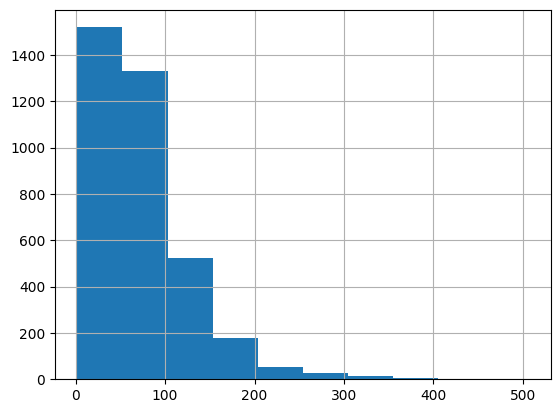

In [250]:
sentences_df["char_count"].hist()

<Axes: >

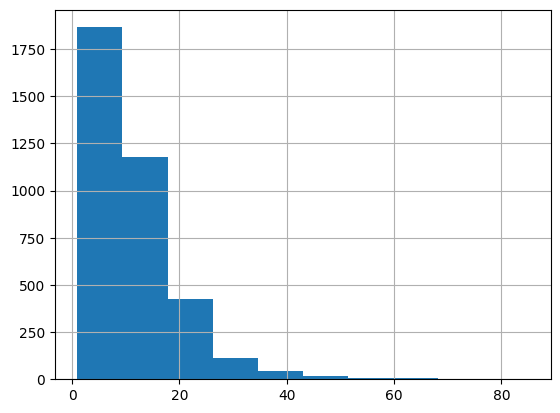

In [251]:
sentences_df["words_count"].hist()


<Axes: ylabel='char_count'>

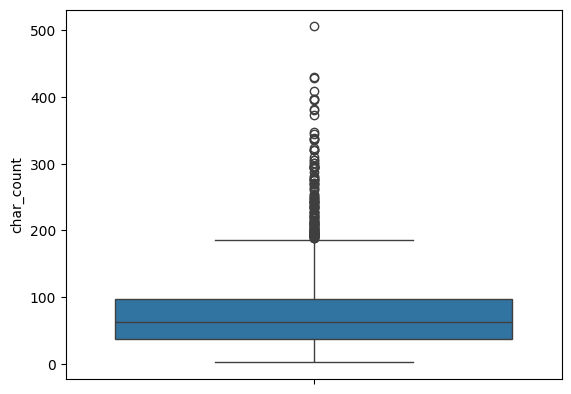

In [252]:
boxplot(sentences_df["char_count"]) #type: ignore

<Axes: ylabel='words_count'>

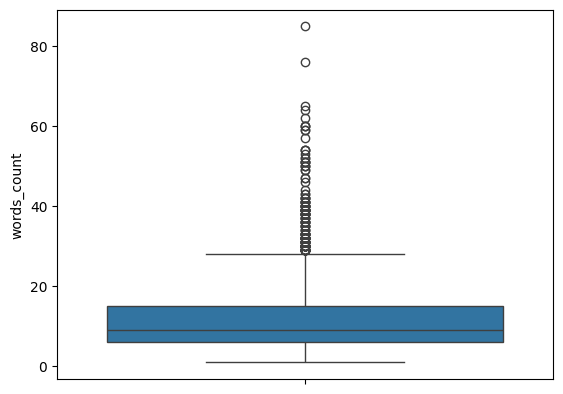

In [253]:
boxplot(sentences_df["words_count"]) #type: ignore


In [254]:
sentences_df.sort_values(by="words_count", ascending=False)

,review_id,sentence_id,text,char_count,words_count
2395,31963,31963:3,"Если брать во внимание кухню, то как придется:...",506,85
2852,34228,34228:6,"Брали: - чебурек - ребенок съел, остался довол...",429,76
1266,18756,18756:2,Этот бар подходит тем кто хочет посмотреть фут...,430,65
3378,36948,36948:2,Что касается оценок (от 1 - 10): - 7 ставлю за...,382,64
647,19383,19383:5,"Заказали: отварные креветки - креветки, как кр...",395,62
...,...,...,...,...,...
3164,35904,35904:1,Ломоносове!,11,1
1041,16322,16322:13,Нормально.,10,1
935,15567,15567:0,Здравствуйте.,13,1
2460,32513,32513:10,Разочарование..,15,1


In [255]:
q3_char_count = sentences_df["char_count"].quantile(0.75)
q1_char_count = sentences_df["char_count"].quantile(0.25)
iqr_char_count = q3_char_count - q1_char_count
outliers_upper_bound_char_count = q3_char_count + 1.5 * iqr_char_count
outliers_lower_bound_char_count = q1_char_count - 1.5 * iqr_char_count
sentences_df[(sentences_df["char_count"] > outliers_upper_bound_char_count) | (sentences_df["char_count"] < outliers_lower_bound_char_count)]


,review_id,sentence_id,text,char_count,words_count
6,27925,27925:6,На наш не большой банкетик мы заказали пару пр...,345,57
7,27925,27925:7,"Ближе к вечеру нас предупредили о том, что буд...",206,32
60,10354,10354:11,Из кухни могу порекомендовать: чебуреки с сыро...,197,29
69,1052,1052:7,"Навсегда останется в памяти официант, который ...",215,33
72,1052,1052:10,Когда наша официантка все таки соизволила появ...,248,41
...,...,...,...,...,...
3514,34196,34196:10,Очень огорчили посетители VIP-зала (стыдно за ...,246,41
3523,34607,34607:6,"Рис также ждали вместе с чаем больше 20 мин.,н...",253,41
3541,35501,35501:13,"Очень удобным оказалось то, что можно заказать...",195,30
3645,9878,9878:2,"Сидели ждали заказ минут 30, потом к нам подош...",210,36


In [256]:
q3_words_count = sentences_df["words_count"].quantile(0.75)
q1_words_count = sentences_df["words_count"].quantile(0.25)
iqr_words_count = q3_words_count - q1_words_count
outliers_upper_bound_words_count = q3_words_count + 1.5 * iqr_words_count
outliers_lower_bound_words_count = q1_words_count - 1.5 * iqr_words_count
sentences_df[sentences_df["words_count"] > outliers_upper_bound_words_count]

,review_id,sentence_id,text,char_count,words_count
6,27925,27925:6,На наш не большой банкетик мы заказали пару пр...,345,57
7,27925,27925:7,"Ближе к вечеру нас предупредили о том, что буд...",206,32
60,10354,10354:11,Из кухни могу порекомендовать: чебуреки с сыро...,197,29
69,1052,1052:7,"Навсегда останется в памяти официант, который ...",215,33
72,1052,1052:10,Когда наша официантка все таки соизволила появ...,248,41
...,...,...,...,...,...
3523,34607,34607:6,"Рис также ждали вместе с чаем больше 20 мин.,н...",253,41
3541,35501,35501:13,"Очень удобным оказалось то, что можно заказать...",195,30
3581,36926,36926:5,"Ходили с молодым человеком, заказали омлет по-...",186,30
3645,9878,9878:2,"Сидели ждали заказ минут 30, потом к нам подош...",210,36


In [257]:
new_merged_df = pd.merge(sentences_df, opinions_df, how="left", on="sentence_id")
new_merged_df

,review_id,sentence_id,text,char_count,words_count,category,polarity,target,from,to,general_category
0,27925,27925:0,Добрый час суток.,17,3,NaN,NaN,NaN,NaN,NaN,NaN
1,27925,27925:1,Меня зовут Влада!,17,3,NaN,NaN,NaN,NaN,NaN,NaN
2,27925,27925:2,Я со своим молодым человеком и пару его друзей...,105,18,NaN,NaN,NaN,NaN,NaN,NaN
3,27925,27925:3,Обслуживание хорошее нас встретил метрдотель и...,93,13,SERVICE#GENERAL,positive,Обслуживание,0,12,SERVICE
4,27925,27925:3,Обслуживание хорошее нас встретил метрдотель и...,93,13,SERVICE#GENERAL,positive,метрдотель,34,44,SERVICE
...,...,...,...,...,...,...,...,...,...,...,...
5006,9955,9955:1,"Впечатления остались только хорошие,интерьер п...",79,7,AMBIENCE#GENERAL,positive,интерьер,36,44,AMBIENCE
5007,9955,9955:2,"Готовят вкусно и достаточно быстро,на мой взгляд.",49,7,FOOD#QUALITY,positive,NULL,0,0,FOOD
5008,9955,9955:3,"Обслуживала нас приятная,веселая девушка,успев...",110,14,SERVICE#GENERAL,positive,девушка,33,40,SERVICE
5009,9955,9955:3,"Обслуживала нас приятная,веселая девушка,успев...",110,14,FOOD#PRICES,positive,скидку,91,97,FOOD


In [258]:
new_merged_df_opinions_counts = opinions_df["sentence_id"].value_counts(dropna=False)
sentences_df["opinion_count"] = sentences_df["sentence_id"].map(new_merged_df_opinions_counts).fillna(0)
sentences_df

,review_id,sentence_id,text,char_count,words_count,opinion_count
0,27925,27925:0,Добрый час суток.,17,3,0.0
1,27925,27925:1,Меня зовут Влада!,17,3,0.0
2,27925,27925:2,Я со своим молодым человеком и пару его друзей...,105,18,0.0
3,27925,27925:3,Обслуживание хорошее нас встретил метрдотель и...,93,13,2.0
4,27925,27925:4,"Он был в уютном уголке в конце главного зала, ...",174,28,2.0
...,...,...,...,...,...,...
3650,9955,9955:0,Давно хотели сходить в это кафе(тем более живе...,62,10,0.0
3651,9955,9955:1,"Впечатления остались только хорошие,интерьер п...",79,7,2.0
3652,9955,9955:2,"Готовят вкусно и достаточно быстро,на мой взгляд.",49,7,1.0
3653,9955,9955:3,"Обслуживала нас приятная,веселая девушка,успев...",110,14,2.0


In [259]:
opinions_df["sentence_id"].count() == sentences_df["opinion_count"].sum()

np.True_

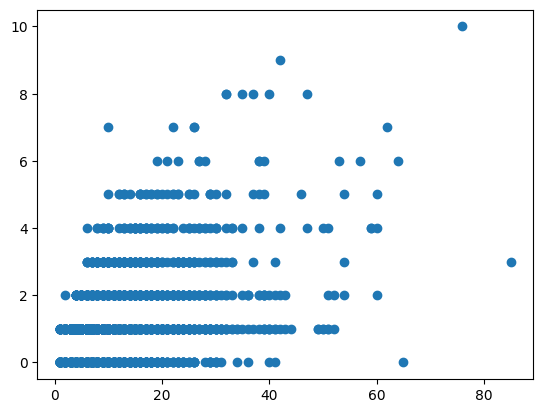

In [260]:
scatter(sentences_df["words_count"], sentences_df["opinion_count"])

<Axes: >

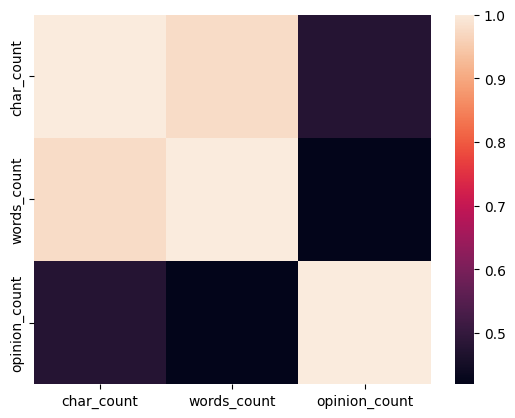

In [261]:
heatmap(sentences_df[["char_count", "words_count", "opinion_count"]].corr("pearson"))

In [262]:
sentences_df[["char_count", "words_count", "opinion_count"]].corr("pearson")

,char_count,words_count,opinion_count
char_count,1.000000,0.976473,0.476698
words_count,0.976473,1.000000,0.419549
opinion_count,0.476698,0.419549,1.000000


<Axes: >

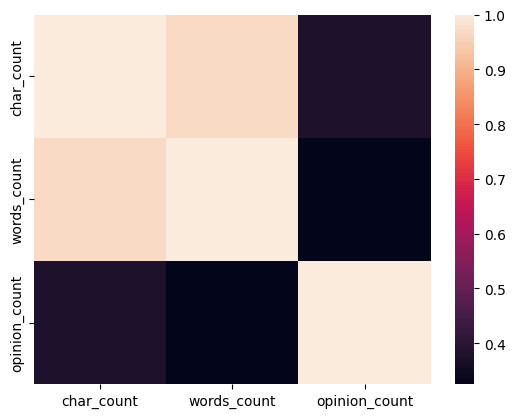

In [263]:
heatmap(sentences_df[["char_count", "words_count", "opinion_count"]].corr("spearman"))

In [264]:
sentences_df[["char_count", "words_count", "opinion_count"]].corr("spearman")

,char_count,words_count,opinion_count
char_count,1.000000,0.969843,0.377110
words_count,0.969843,1.000000,0.325387
opinion_count,0.377110,0.325387,1.000000


interval columns not set, guessing: ['char_count', 'words_count', 'opinion_count']


<Axes: >

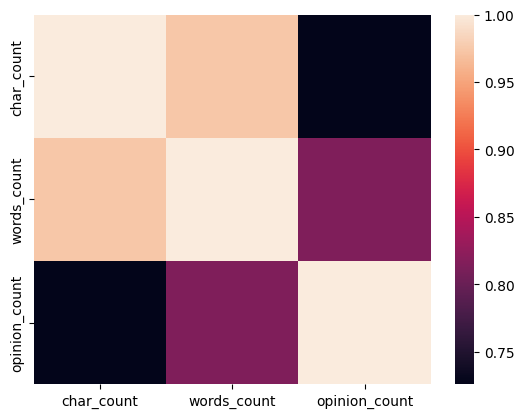

In [265]:
heatmap(phik_matrix(sentences_df[["char_count", "words_count", "opinion_count"]]))

In [266]:
phik_matrix(sentences_df[["char_count", "words_count", "opinion_count"]])

interval columns not set, guessing: ['char_count', 'words_count', 'opinion_count']


,char_count,words_count,opinion_count
char_count,1.000000,0.974171,0.725880
words_count,0.974171,1.000000,0.814627
opinion_count,0.725880,0.814627,1.000000


In [267]:
sentences_df["sentence_id"].duplicated().sum()

np.int64(0)

In [268]:
sentences_df["text"].duplicated().sum()

np.int64(54)

In [269]:
duplicated_df = pd.merge(sentences_df[sentences_df["text"].duplicated(keep=False)], opinions_df, how="left", on="sentence_id")
duplicated_df.sort_values(by="text")

,review_id,sentence_id,text,char_count,words_count,opinion_count,category,polarity,target,from,to,general_category
45,32856,32856:9,P.,2,1,0.0,NaN,NaN,NaN,NaN,NaN,NaN
85,32771,32771:27,P.,2,1,0.0,NaN,NaN,NaN,NaN,NaN,NaN
79,36512,36512:15,P.,2,1,0.0,NaN,NaN,NaN,NaN,NaN,NaN
89,9870,9870:11,P.,2,1,0.0,NaN,NaN,NaN,NaN,NaN,NaN
20,23878,23878:10,P.,2,1,0.0,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
84,37036,37036:5,"Хочу отметить, что для ресторана такого уровня...",63,10,1.0,FOOD#PRICES,neutral,NULL,0,0,FOOD
38,30808,30808:6,"Хочу отметить, что для ресторана такого уровня...",63,10,2.0,RESTAURANT#GENERAL,positive,ресторана,23,32,RESTAURANT
39,30808,30808:6,"Хочу отметить, что для ресторана такого уровня...",63,10,2.0,RESTAURANT#PRICES,positive,ресторана,23,32,RESTAURANT
77,36402,36402:7,Цены средние.,13,2,1.0,RESTAURANT#PRICES,neutral,NULL,0,0,RESTAURANT


In [270]:
opinions_df.duplicated().sum()

np.int64(0)

In [271]:
sentences_df.isna().sum()

review_id        0
sentence_id      0
text             0
char_count       0
words_count      0
opinion_count    0
dtype: int64

In [272]:
sentences_df["text"].str.strip().eq("").sum()

np.int64(0)

In [273]:
all_exist = opinions_df["sentence_id"].isin(sentences_df["sentence_id"]).all()
all_exist

np.True_

In [274]:
print(opinions_df["category"].nunique())
print(opinions_df["category"].unique())

12
['SERVICE#GENERAL' 'AMBIENCE#GENERAL' 'FOOD#QUALITY' 'FOOD#PRICES'
 'FOOD#STYLE_OPTIONS' 'RESTAURANT#GENERAL' 'RESTAURANT#PRICES'
 'DRINKS#STYLE_OPTIONS' 'RESTAURANT#MISCELLANEOUS' 'DRINKS#QUALITY'
 'LOCATION#GENERAL' 'DRINKS#PRICES']


In [275]:
print(opinions_df["polarity"].nunique())
print(opinions_df["polarity"].unique())

4
['positive' 'neutral' 'negative' 'conflict']


In [276]:
opinions_df[opinions_df["target"] == "NULL"].count()

sentence_id         930
category            930
polarity            930
target              930
from                930
to                  930
general_category    930
dtype: int64

In [277]:
def get_text_from_to(row: pd.Series) -> str:
    if row["target"] != "NULL" and pd.notna(row["from"]) and pd.notna(row["to"]):
        text = row["text"]
        from_index = int(row["from"])
        to_index = int(row["to"])
        if 0 <= from_index < to_index <= len(text):
            return text[from_index:to_index]
    return ""

In [278]:
new_merged_df["extracted_text"] = new_merged_df.apply(get_text_from_to, axis=1)
new_merged_df[["text", "from", "to", "target", "extracted_text"]].head(10)

,text,from,to,target,extracted_text
0,Добрый час суток.,NaN,NaN,NaN,
1,Меня зовут Влада!,NaN,NaN,NaN,
2,Я со своим молодым человеком и пару его друзей...,NaN,NaN,NaN,
3,Обслуживание хорошее нас встретил метрдотель и...,0,12,Обслуживание,Обслуживание
4,Обслуживание хорошее нас встретил метрдотель и...,34,44,метрдотель,метрдотель
5,"Он был в уютном уголке в конце главного зала, ...",16,22,уголке,уголке
6,"Он был в уютном уголке в конце главного зала, ...",46,63,приглушенный свет,приглушенный свет
7,"Просто мы пришли днем часиков в четыре, так чт...",NaN,NaN,NaN,
8,На наш не большой банкетик мы заказали пару пр...,53,57,блюд,блюд
9,На наш не большой банкетик мы заказали пару пр...,75,81,улитки,улитки
